### Compare minimal medium with metabolomics dataset

In [33]:
import pandas as pd
import numpy as np
import json
import requests
import csv
import warnings
from os import listdir

import reframed


#### Mapping names to seed ids (seem to have a good overlap)

In [34]:
with open('../data/Venturelli2018/generated/metname2metanetx.json') as json_file:
    metname2metanetx = json.load(json_file)

In [35]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

### Metabolomics data

In [36]:
dataset4 = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)
#dataset4.index = dataset4.index.map(lambda met: met.split("_")[0][1:])
dataset4.index = dataset4.index.map(lambda met: met.replace("'",""))
dataset4.index = dataset4.index.map(lambda met: met.replace("'",""))
dataset4.index = dataset4.index.map(lambda met: met.replace(" ",""))
dataset4.index = dataset4.index.map(lambda met: met.lower())


### Compare with minimal medium (threshold -1.0)

In [38]:
minimal_medium = pd.read_csv("../output/Venturelli2018/minimal_media_lb_extended.tsv",sep="\t",index_col=0)

rxns = ["R_EX_"+met[2:] for met in metid2metname.keys()]
rxns = [rxn.replace("91","40") for rxn in rxns]
rxns = [rxn.replace("93","41") for rxn in rxns]
rxnid2metname = dict(zip(rxns,metid2metname.values()))
rxns = [rxn for rxn in rxns if rxn in minimal_medium.index]
minimal_medium = minimal_medium.loc[rxns]

minimal_medium.index = minimal_medium.index.map(lambda x: rxnid2metname[x])
minimal_medium.columns = minimal_medium.columns.map(lambda x: (x.split("_")[0][0]+x.split("_")[1][0]).upper())
minimal_medium = minimal_medium.map(lambda x:1 if x>200 else 0)

In [39]:
dataset4_c = dataset4.copy()

dataset4_c.columns = dataset4_c.columns.map(lambda x:x.replace("'","")).map(lambda x:x.replace(" ",""))

dataset4_c = dataset4_c.map(lambda x:1 if x<-1.0 else 0)
dataset4_c = dataset4_c.loc[minimal_medium.index]
dataset4_c = dataset4_c[minimal_medium.columns]


In [40]:
import seaborn as sns

In [41]:
combined = dataset4_c+minimal_medium

combined[dataset4_c==1] *= -1
combined = combined.map(lambda x: abs(x) if abs(x)==2 else x)

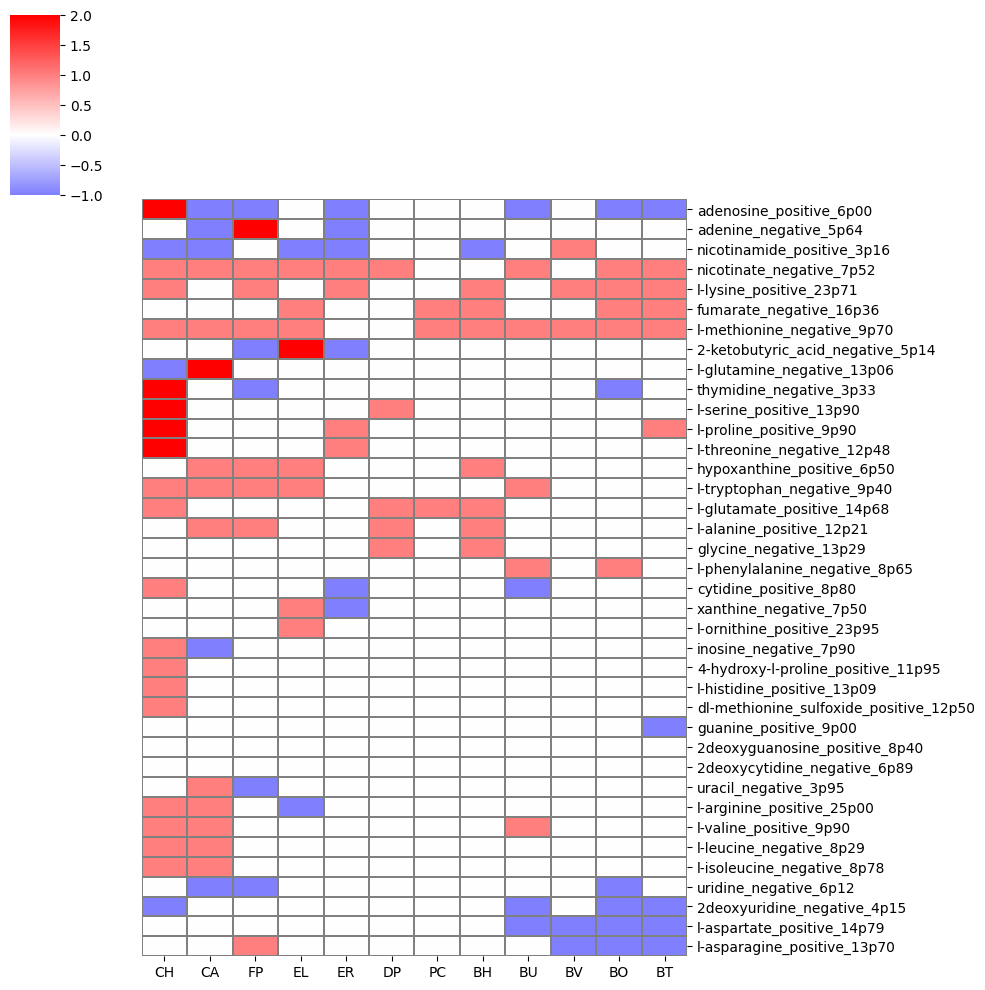

In [42]:

cg = sns.clustermap(combined,cmap="bwr",center=0,vmax=2,linewidths=0.005,linecolor="grey",fmt="d")
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)

### Compare with minimal medium (threshold -0.5)

In [43]:
minimal_medium = pd.read_csv("../output/Venturelli2018/minimal_media_lb_extended.tsv",sep="\t",index_col=0)

rxns = ["R_EX_"+met[2:] for met in metid2metname.keys()]
rxns = [rxn.replace("91","40") for rxn in rxns]
rxns = [rxn.replace("93","41") for rxn in rxns]
rxnid2metname = dict(zip(rxns,metid2metname.values()))
rxns = [rxn for rxn in rxns if rxn in minimal_medium.index]

minimal_medium = minimal_medium.loc[rxns]
minimal_medium.index = minimal_medium.index.map(lambda x: rxnid2metname[x])
minimal_medium.columns = minimal_medium.columns.map(lambda x: (x.split("_")[0][0]+x.split("_")[1][0]).upper())
minimal_medium = minimal_medium.map(lambda x:1 if x>200 else 0)

In [44]:
dataset4_c = dataset4.copy()

dataset4_c.columns = dataset4_c.columns.map(lambda x:x.replace("'","")).map(lambda x:x.replace(" ",""))

dataset4_c = dataset4_c.map(lambda x:1 if x<-0.5 else 0)
dataset4_c = dataset4_c.loc[minimal_medium.index]
dataset4_c = dataset4_c[minimal_medium.columns]


In [45]:
import seaborn as sns

In [46]:
combined = dataset4_c+minimal_medium

combined[dataset4_c==1] *= -1
combined = combined.map(lambda x: abs(x) if abs(x)==2 else x)

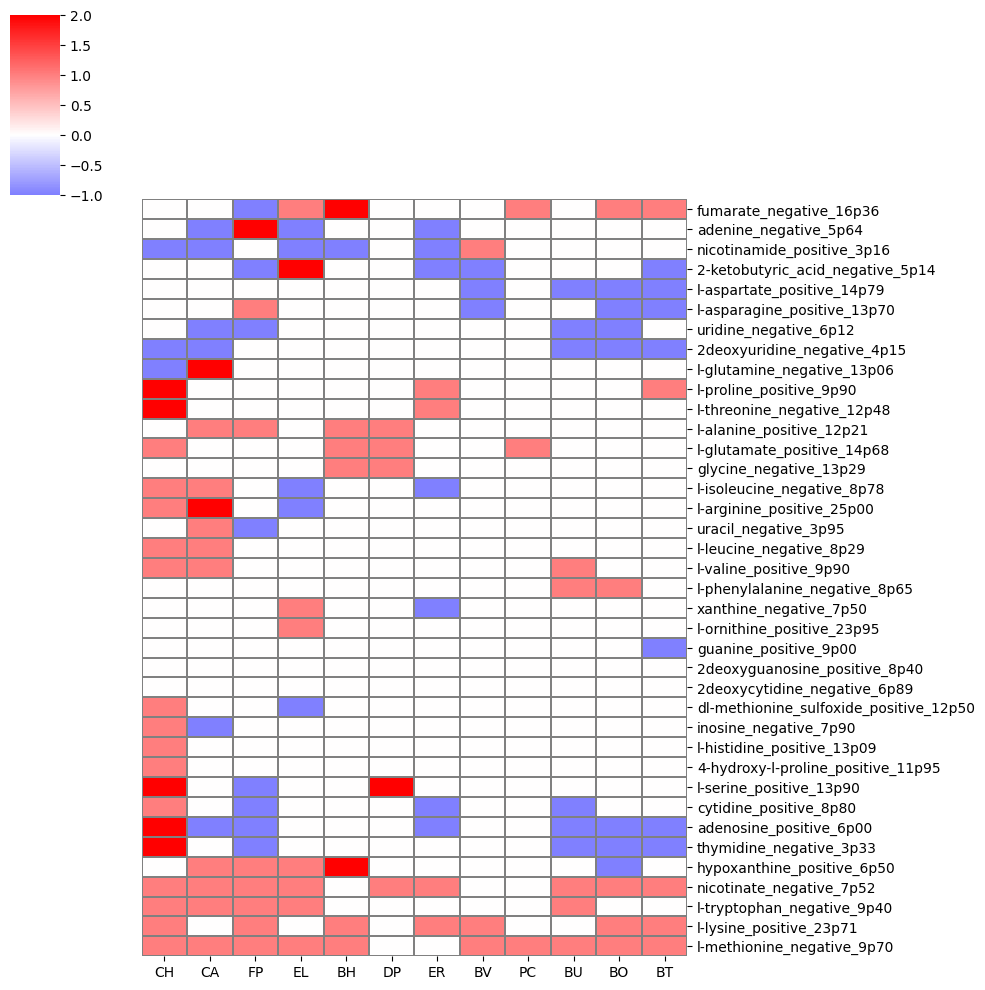

In [47]:

cg = sns.clustermap(combined,cmap="bwr",center=0,vmax=2,linewidths=0.005,linecolor="grey",fmt="d")
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)

### Compare with minimal medium (threshold -0.1)

In [48]:
minimal_medium = pd.read_csv("../output/Venturelli2018/minimal_media_lb_extended.tsv",sep="\t",index_col=0)

rxns = ["R_EX_"+met[2:] for met in metid2metname.keys()]
rxns = [rxn.replace("91","40") for rxn in rxns]
rxns = [rxn.replace("93","41") for rxn in rxns]
rxnid2metname = dict(zip(rxns,metid2metname.values()))
rxns = [rxn for rxn in rxns if rxn in minimal_medium.index]

minimal_medium = minimal_medium.loc[rxns]
minimal_medium.index = minimal_medium.index.map(lambda x: rxnid2metname[x])
minimal_medium.columns = minimal_medium.columns.map(lambda x: (x.split("_")[0][0]+x.split("_")[1][0]).upper())
minimal_medium = minimal_medium.map(lambda x:1 if x>200 else 0)

In [49]:
dataset4_c = dataset4.copy()

dataset4_c.columns = dataset4_c.columns.map(lambda x:x.replace("'","")).map(lambda x:x.replace(" ",""))

dataset4_c = dataset4_c.map(lambda x:1 if x<-0.1 else 0)
dataset4_c = dataset4_c.loc[minimal_medium.index]
dataset4_c = dataset4_c[minimal_medium.columns]


In [50]:
import seaborn as sns

In [51]:
combined = dataset4_c+minimal_medium

combined[dataset4_c==1] *= -1
combined = combined.map(lambda x: abs(x) if abs(x)==2 else x)

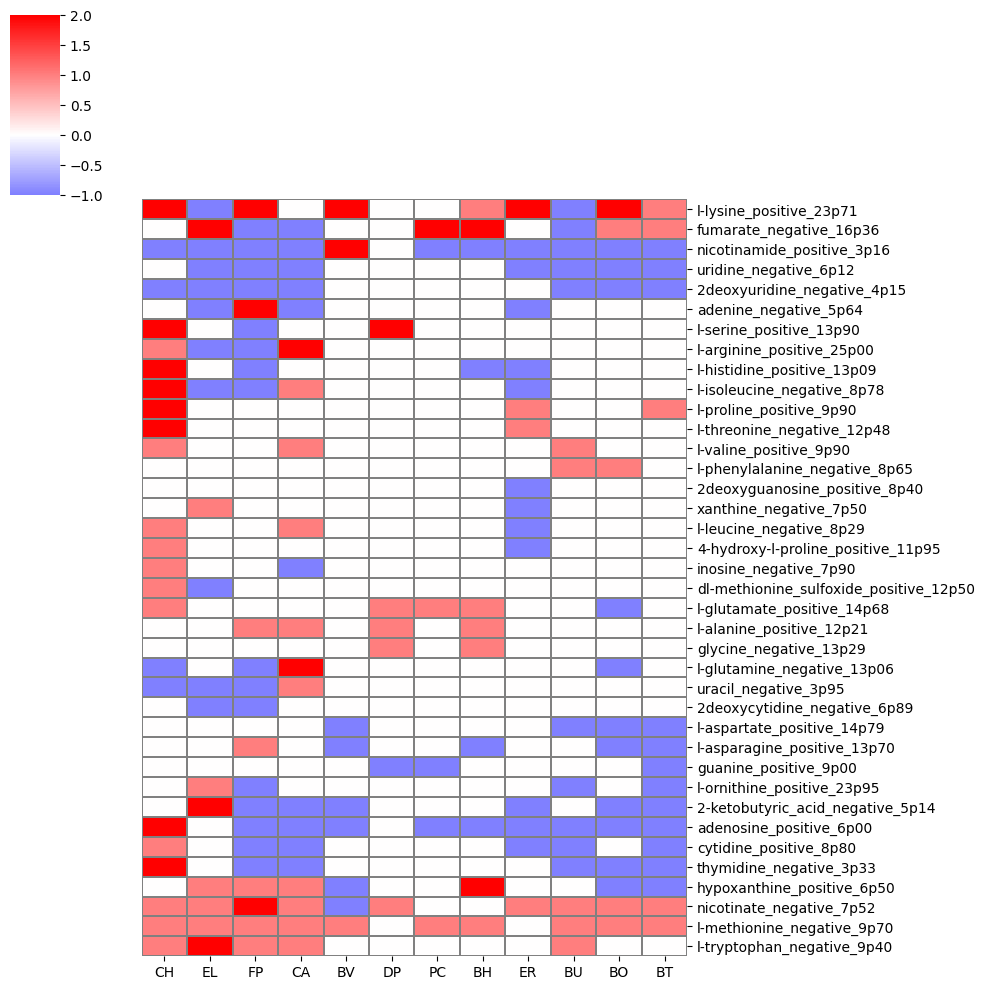

In [52]:
cg = sns.clustermap(combined,cmap="bwr",center=0,vmax=2,linewidths=0.005,linecolor="grey",fmt="d")
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)